In [1]:
# Colab setup — mount Drive and install packages
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    %pip install -q transformers datasets accelerate

Mounted at /content/drive


In [4]:
from pathlib import Path

if IS_COLAB:
    PROJECT_ROOT = Path("/content/drive/MyDrive/thesis_stage2")
else:
    PROJECT_ROOT = Path(".")

MODELS_DIR    = PROJECT_ROOT / "models"
RESULTS_DIR   = PROJECT_ROOT / "results"

# === CHANGE THESE TWO VARIABLES BETWEEN RUNS ===
VARIANT       = "v1_balanced"   # "v1_balanced" or "v1_rebalanced"
CLASS_WEIGHTED = False          # True or False

# === HYPERPARAMETERS (mirror chapter 4.4.4) ===
MODEL_NAME    = "roberta-base"
SEED          = 42
MAX_LEN       = 512
LR            = 2e-5
WEIGHT_DECAY  = 0.01
EPOCHS        = 10
BATCH_TRAIN   = 16
BATCH_EVAL    = 32
WARMUP_RATIO  = 0.1
GRAD_CLIP     = 1.0
EARLY_STOP    = 3

# Run identifier embedded in output filenames so the three runs don't overwrite
RUN_TAG = f"{VARIANT}{'_weighted' if CLASS_WEIGHTED else ''}"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = PROJECT_ROOT / f"patternreframe_train_aug_{VARIANT}.csv"
VAL_CSV   = PROJECT_ROOT / f"patternreframe_val_aug_{VARIANT}.csv"
TEST_CSV  = PROJECT_ROOT / f"patternreframe_test_aug_{VARIANT}.csv"
OUT_DIR   = MODELS_DIR / f"binary_patternreframe_{RUN_TAG}"

print(f"VARIANT:        {VARIANT}")
print(f"CLASS_WEIGHTED: {CLASS_WEIGHTED}")
print(f"RUN_TAG:        {RUN_TAG}")
print(f"Train: {TRAIN_CSV}")
print(f"Val:   {VAL_CSV}")
print(f"Test:  {TEST_CSV}")
print(f"Out:   {OUT_DIR}")

VARIANT:        v1_balanced
CLASS_WEIGHTED: False
RUN_TAG:        v1_balanced
Train: /content/drive/MyDrive/thesis_stage2/patternreframe_train_aug_v1_balanced.csv
Val:   /content/drive/MyDrive/thesis_stage2/patternreframe_val_aug_v1_balanced.csv
Test:  /content/drive/MyDrive/thesis_stage2/patternreframe_test_aug_v1_balanced.csv
Out:   /content/drive/MyDrive/thesis_stage2/models/binary_patternreframe_v1_balanced


In [5]:
# 1. Load splits and build binary labels
import pandas as pd


def load_split(path):
    df = pd.read_csv(path)
    df = df[["thought", "pattern"]].copy()
    df["text"] = df["thought"].astype(str)
    df["label"] = (df["pattern"] != "No Distortion").astype(int)
    return df[["text", "label", "pattern"]]


train_df = load_split(TRAIN_CSV)
val_df   = load_split(VAL_CSV)
test_df  = load_split(TEST_CSV)

print(f"Train: {len(train_df)} — labels: {train_df.label.value_counts().to_dict()}")
print(f"Val:   {len(val_df)} — labels: {val_df.label.value_counts().to_dict()}")
print(f"Test:  {len(test_df)} — labels: {test_df.label.value_counts().to_dict()}")


Train: 2112 — labels: {1: 1920, 0: 192}
Val:   1057 — labels: {1: 961, 0: 96}
Test:  7488 — labels: {1: 6807, 0: 681}


In [6]:
# 2. Tokeniser and model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "No Distortion", 1: "Distorted"},
    label2id={"No Distortion": 0, "Distorted": 1},
)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [7]:
# 3. Tokenise the splits
from datasets import Dataset


def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)


ds_train = Dataset.from_pandas(train_df).map(tokenize, batched=True)
ds_val   = Dataset.from_pandas(val_df).map(tokenize, batched=True)
ds_test  = Dataset.from_pandas(test_df).map(tokenize, batched=True)

# Drop non-tensor columns (the Trainer will complain otherwise)
ds_train = ds_train.remove_columns(["text", "pattern"])
ds_val   = ds_val.remove_columns(["text", "pattern"])
ds_test_for_eval = ds_test.remove_columns(["text", "pattern"])

Map:   0%|          | 0/2112 [00:00<?, ? examples/s]

Map:   0%|          | 0/1057 [00:00<?, ? examples/s]

Map:   0%|          | 0/7488 [00:00<?, ? examples/s]

In [8]:
# 4. Metrics function
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
)


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", pos_label=1, zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision_distorted": p,
        "recall_distorted": r,
        "f1_distorted": f1,
        "f1_weighted": f1_score(labels, preds, average="weighted", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
    }

In [9]:
# Class-weighted trainer subclass. If CLASS_WEIGHTED is False the trainer
# behaves like the standard one — class_weights stays None and we fall back
# to vanilla cross-entropy.
import torch
import torch.nn as nn
from transformers import Trainer

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weight = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = nn.CrossEntropyLoss(weight=weight)(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


# Compute class weights from the training-set label counts. Inverse frequency,
# normalised so the weights sum to the number of classes — the same formula
# sklearn's compute_class_weight uses with class_weight="balanced".
if CLASS_WEIGHTED:
    counts = train_df["label"].value_counts().sort_index()
    n_nd        = int(counts.loc[0])
    n_distorted = int(counts.loc[1])
    total = n_nd + n_distorted
    w_nd        = total / (2 * n_nd)
    w_distorted = total / (2 * n_distorted)
    class_weights = torch.tensor([w_nd, w_distorted], dtype=torch.float)
    print(f"Train counts: ND={n_nd}, Distorted={n_distorted}")
    print(f"Class weights: ND={w_nd:.3f}, Distorted={w_distorted:.3f}")
else:
    class_weights = None
    print("Unweighted training (class_weights=None).")

Unweighted training (class_weights=None).


In [10]:
# 5. Trainer and training
from transformers import (
    DataCollatorWithPadding, EarlyStoppingCallback, TrainingArguments,
)

training_args = TrainingArguments(
    output_dir="/content/trainer_tmp",
    num_train_epochs=EPOCHS,
    learning_rate=LR,
    weight_decay=WEIGHT_DECAY,
    per_device_train_batch_size=BATCH_TRAIN,
    per_device_eval_batch_size=BATCH_EVAL,
    warmup_ratio=WARMUP_RATIO,
    max_grad_norm=GRAD_CLIP,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    save_total_limit=1,
    seed=SEED,
    report_to=[],
    logging_steps=50,
)

trainer = WeightedTrainer(
    class_weights=class_weights,
    model=model,
    args=training_args,
    train_dataset=ds_train,
    eval_dataset=ds_val,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOP)],
)

trainer.train()

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Distorted,Recall Distorted,F1 Distorted,F1 Weighted,F1 Macro
1,0.232395,0.050550,0.990539,0.990712,0.998959,0.994819,0.990353,0.970235
2,0.069695,0.042409,0.994324,0.994819,0.998959,0.996885,0.994269,0.982485
3,0.043869,0.072973,0.988647,0.987667,1.000000,0.993795,0.988304,0.963564
4,0.000183,0.052647,0.990539,0.989701,1.000000,0.994824,0.990304,0.969939
5,0.000140,0.057488,0.992431,0.996872,0.994797,0.995833,0.992466,0.977298


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=660, training_loss=0.08929323652357032, metrics={'train_runtime': 189.0388, 'train_samples_per_second': 111.723, 'train_steps_per_second': 6.983, 'total_flos': 199421735521920.0, 'train_loss': 0.08929323652357032, 'epoch': 5.0})

In [11]:
# 6. Test-set evaluation
test_metrics = trainer.evaluate(ds_test_for_eval)
print("Test metrics:")
for k, v in test_metrics.items():
    print(f"  {k}: {v}")

Test metrics:
  eval_loss: 0.050780292600393295
  eval_accuracy: 0.9909188034188035
  eval_precision_distorted: 0.9941340372488635
  eval_recall_distorted: 0.9958865873365653
  eval_f1_distorted: 0.9950095405841773
  eval_f1_weighted: 0.9908824413106667
  eval_f1_macro: 0.9723195851069035
  eval_runtime: 18.8586
  eval_samples_per_second: 397.06
  eval_steps_per_second: 12.408
  epoch: 5.0


In [12]:
# 7. Predictions and per-category recall
from torch.nn.functional import softmax
from sklearn.metrics import classification_report, confusion_matrix

pred_out = trainer.predict(ds_test_for_eval)
probs = softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()

out_df = test_df.copy()
out_df["pred"] = np.argmax(pred_out.predictions, axis=-1)
out_df["prob_distorted"] = probs[:, 1]

# Per-category recall: of records with each long-form pattern, what fraction
# did the binary detector recover correctly.
per_category_recall = {}
for cat in sorted(out_df["pattern"].unique()):
    sub = out_df[out_df["pattern"] == cat]
    if cat == "No Distortion":
        per_category_recall[cat] = float((sub["pred"] == 0).mean())
    else:
        per_category_recall[cat] = float((sub["pred"] == 1).mean())

print("Per-category recall:")
for cat, rec in per_category_recall.items():
    print(f"  {cat:60s}  {rec:.4f}")

Per-category recall:
  Black-and-white or polarized thinking / All or nothing thinking  0.9925
  Catastrophizing                                               0.9986
  Discounting the positive                                      0.9941
  Jumping to conclusions: Fortune-telling                       0.9986
  Jumping to conclusions: mind reading                          0.9971
  Labeling and mislabeling                                      0.9955
  Mental filtering                                              0.9955
  No Distortion                                                 0.9413
  Overgeneralization                                            0.9985
  Personalization                                               0.9893
  Should statements                                             0.9985


In [13]:
# 8. Save results
import json

cm = confusion_matrix(out_df["label"], out_df["pred"])
report = classification_report(
    out_df["label"], out_df["pred"],
    target_names=["No Distortion", "Distorted"],
    digits=4, output_dict=True, zero_division=0,
)

results = {
    "variant": VARIANT,
    "test_metrics": test_metrics,
    "confusion_matrix": cm.tolist(),
    "classification_report": report,
    "per_category_recall": per_category_recall,
    "n_train": len(train_df),
    "n_val": len(val_df),
    "n_test": len(test_df),
}

metrics_path = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_test_metrics.json"
preds_path   = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_test_predictions.csv"

with open(metrics_path, "w") as f:
    json.dump(results, f, indent=2)
out_df.to_csv(preds_path, index=False)

trainer.save_model(str(OUT_DIR / "best"))
tokenizer.save_pretrained(str(OUT_DIR / "best"))

print(f"Saved metrics to {metrics_path}")
print(f"Saved predictions to {preds_path}")
print(f"Saved model to {OUT_DIR / 'best'}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved metrics to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_v1_balanced_test_metrics.json
Saved predictions to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_v1_balanced_test_predictions.csv
Saved model to /content/drive/MyDrive/thesis_stage2/models/binary_patternreframe_v1_balanced/best


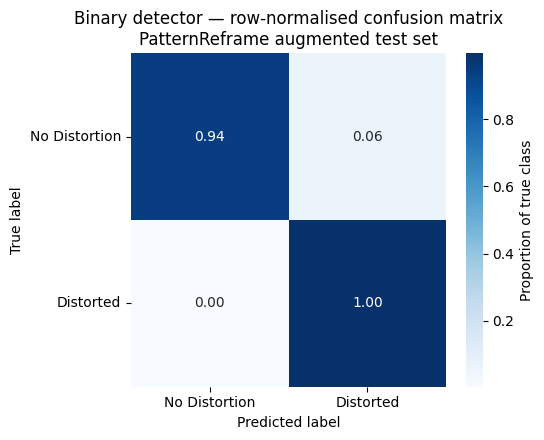

Saved figure to /content/drive/MyDrive/thesis_stage2/results/binary_patternreframe_v1_balanced_confusion_matrix.png


In [14]:
# 9. Confusion matrix plot
import matplotlib.pyplot as plt
import seaborn as sns

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm_norm,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=["No Distortion", "Distorted"],
    yticklabels=["No Distortion", "Distorted"],
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Binary detector — row-normalised confusion matrix\nPatternReframe augmented test set")
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

fig_path = RESULTS_DIR / f"binary_patternreframe_{RUN_TAG}_confusion_matrix.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure to {fig_path}")

In [15]:
# Cross-evaluation: variant A binary detector on TherapistQA
import pandas as pd
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, accuracy_score,
)

# === Load TherapistQA test split ===
# Edit the path to wherever your TherapistQA test CSV lives. If you haven't
# created one, you can use the full therapistqa.csv as a test pool for this
# diagnostic.
TQA_PATH = PROJECT_ROOT / "therapistqa_test.csv"
print(f"Loading TherapistQA from: {TQA_PATH}")

tqa = pd.read_csv(TQA_PATH)
tqa["text"] = tqa["patient_question"].astype(str)
tqa["label"] = (tqa["dominant_distortion"] != "No Distortion").astype(int)
print(f"TQA: {len(tqa)} rows, label distribution: {tqa['label'].value_counts().to_dict()}")

# === Run the trained variant A detector on TQA ===
# (Assumes `model` and `tokenizer` are still in memory from training. If not,
# load from OUT_DIR / "best".)
import torch, numpy as np
from torch.nn.functional import softmax

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

preds = []
probs = []
BS = 32
with torch.no_grad():
    for i in range(0, len(tqa), BS):
        batch_texts = tqa["text"].iloc[i:i+BS].tolist()
        enc = tokenizer(
            batch_texts, truncation=True, max_length=MAX_LEN,
            padding=True, return_tensors="pt"
        ).to(device)
        logits = model(**enc).logits
        p = softmax(logits, dim=-1).cpu().numpy()
        preds.extend(np.argmax(p, axis=-1).tolist())
        probs.extend(p[:, 1].tolist())

tqa_eval = tqa.copy()
tqa_eval["pred"] = preds
tqa_eval["prob_distorted"] = probs

print("\n=== Cross-eval: PatternReframe binary detector on TherapistQA ===")
print(f"Accuracy:       {accuracy_score(tqa_eval['label'], tqa_eval['pred']):.4f}")
print(f"Weighted F1:    {f1_score(tqa_eval['label'], tqa_eval['pred'], average='weighted'):.4f}")
print(f"Macro F1:       {f1_score(tqa_eval['label'], tqa_eval['pred'], average='macro'):.4f}")
print()
print(classification_report(
    tqa_eval["label"], tqa_eval["pred"],
    target_names=["No Distortion", "Distorted"],
    digits=4, zero_division=0,
))
print("Confusion matrix:")
print(confusion_matrix(tqa_eval["label"], tqa_eval["pred"]))

# What fraction of TherapistQA's ND records did the model call distorted?
nd_mask = tqa_eval["label"] == 0
nd_predicted_distorted = (tqa_eval.loc[nd_mask, "pred"] == 1).mean()
print(f"\nOf the {nd_mask.sum()} TQA No Distortion records, {nd_predicted_distorted:.1%} "
      f"were predicted as Distorted.")
print(f"Mean prob_distorted on ND records: {tqa_eval.loc[nd_mask, 'prob_distorted'].mean():.3f}")
print(f"Mean prob_distorted on D records:  {tqa_eval.loc[~nd_mask, 'prob_distorted'].mean():.3f}")

Loading TherapistQA from: /content/drive/MyDrive/thesis_stage2/therapistqa_test.csv
TQA: 379 rows, label distribution: {1: 239, 0: 140}

=== Cross-eval: PatternReframe binary detector on TherapistQA ===
Accuracy:       0.5752
Weighted F1:    0.5514
Macro F1:       0.5012

               precision    recall  f1-score   support

No Distortion     0.3871    0.2571    0.3090       140
    Distorted     0.6364    0.7615    0.6933       239

     accuracy                         0.5752       379
    macro avg     0.5117    0.5093    0.5012       379
 weighted avg     0.5443    0.5752    0.5514       379

Confusion matrix:
[[ 36 104]
 [ 57 182]]

Of the 140 TQA No Distortion records, 74.3% were predicted as Distorted.
Mean prob_distorted on ND records: 0.744
Mean prob_distorted on D records:  0.762
